# Lucrare de laborator 1 — Manipularea imaginilor cu OpenCV

**Structura lucrării**
0. Pregătirea spațiului de lucru și setul de imagini (atribute, histograme)
1. Transformări geometrice + compararea interpolărilor (timp, PSNR, SSIM)
2. Luminozitate, contrast, gamma (overflow, medie, std, % pixeli saturați)
3. Spații de culori (Gray, HSV, LAB, YCrCb) + segmentare RGB vs HSV (IoU la iluminare)
4. Praguri (global, Otsu, adaptiv — F1) și măști / operații pe biți
5. Adnotare și colaj
6. Video: redimensionare → segmentare → adnotare, FPS
7. Agregarea rezultatelor și concluzii

## 0. Pregătirea spațiului de lucru
Importăm bibliotecile: `cv2` (OpenCV) pentru procesare, `numpy` pentru tablouri, `pandas` pentru tabele de rezultate,
`matplotlib`/`seaborn` pentru grafice, `ipywidgets` pentru explorare interactivă și `skimage` pentru imagini de test și metrici (PSNR, SSIM).

In [1]:
import os, time, json
from glob import glob
from pathlib import Path
from zipfile import ZipFile
from urllib.request import urlretrieve

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact
from skimage import data as skdata
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100
print('OpenCV', cv2.__version__, '| NumPy', np.__version__)

OpenCV 5.0.0 | NumPy 2.5.3


Completați variabilele conform setării voastre:
- `IMG_DIR` — directorul cu imaginile proprii (implicit `imagini/`);
- `VIDEO_PATH` — clipul video de test (implicit `roboti.mp4`, de pe pagina cursului);
- `OUT_DIR` — directorul pentru rezultate (implicit `rezultate/`).

**Convenție recomandată pentru imaginile proprii** (numele fișierului devine cheia imaginii):
`peisaj.jpg`, `document.jpg`, `obiect_color.jpg`, `scena_intunecata.jpg`.

In [8]:
IMG_DIR = 'imagini'
VIDEO_PATH = 'roboti.mp4'
OUT_DIR = 'rezultate'

os.makedirs(IMG_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

Funcția `download_and_unzip()` (aceeași ca la curs) descarcă și dezarhivează resursele cursului. Arhiva se descarcă o singură dată.

In [12]:
def download_and_unzip(url, save_path):
    print('Descarc arhiva...', end=' ')
    urlretrieve(url, save_path)
    try:
        with ZipFile(save_path) as z:
            z.extractall(os.path.split(save_path)[0])
        print('Gata')
    except Exception as e:
        print('\nEroare la dezarhivare:', e)

URL = r'https://www.dropbox.com/s/qhhlqcica1nvtaw/opencv_bootcamp_assets_NB1.zip?dl=1'
asset_zip_path = os.path.join(os.getcwd(), './data/opencv_bootcamp_assets_NB1.zip')

if not os.path.exists(asset_zip_path):
    download_and_unzip(URL, asset_zip_path)

### Funcții ajutătoare
OpenCV lucrează cu imagini **BGR**, iar matplotlib afișează **RGB**. `show()` afișează o listă de imagini (color sau gri) într-o grilă, cu conversia corectă
(`cv2.imshow()` nu funcționează în notebook). `timeit_ms()` măsoară timpul mediu de execuție (cu o rulare de încălzire), iar `save_json()` exportă un DataFrame în `rezultate/`.

In [13]:
def show(images, titles=None, cols=None, size=4, cmap='gray'):
    n = len(images)
    cols = cols or n
    rows = int(np.ceil(n / cols))
    plt.figure(figsize=(size * cols, size * rows * 0.8))
    for i, img in enumerate(images):
        plt.subplot(rows, cols, i + 1)
        if img.ndim == 2:
            plt.imshow(img, cmap=cmap, vmin=0, vmax=255)
        else:
            plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        if titles:
            plt.title(titles[i])
        plt.axis('off')
    plt.tight_layout()
    plt.show()

def timeit_ms(fn, repeats=10):
    fn()  # încălzire (cache, alocări)
    start = time.perf_counter()
    for _ in range(repeats):
        fn()
    return (time.perf_counter() - start) / repeats * 1000

def save_json(df, name):
    path = os.path.join(OUT_DIR, name)
    df.to_json(path, orient='records', indent=4, force_ascii=False)
    print('Salvat:', path)

## Setul de imagini
Trei surse: arhiva cursului (`cv2.imread`, deja BGR), imaginile de test din `scikit-image` (vin în **RGB** → le convertim în BGR) și imaginile proprii din `IMG_DIR`.
Imaginile proprii foarte mari (poze de telefon) sunt micșorate cu `INTER_AREA` la maxim 1200 px pe latura lungă, ca experimentele să ruleze rapid.

In [97]:
def from_skimage(name):
    rgb = getattr(skdata, name)()
    if rgb.ndim == 2:
        return rgb                       # imagine în tonuri de gri
    return cv2.cvtColor(rgb[..., :3], cv2.COLOR_RGB2BGR)   # eliminăm eventualul canal alfa

def limit_size(img, max_side=1200):
    s = max_side / max(img.shape[:2])
    return cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA) if s < 1 else img

IMAGES = {
    'lac': cv2.imread('./data/New_Zealand_Lake.jpg'),
    'logo': cv2.imread('./data/coca-cola-logo.png'),
    'sah_color': cv2.imread('./data/checkerboard_color.png'),
    'astronaut': from_skimage('astronaut'),
    'cafea': from_skimage('coffee'),
    'racheta': from_skimage('rocket'),
    'pisica': from_skimage('chelsea'),
    'hubble': from_skimage('hubble_deep_field'),
    'pagina': from_skimage('page'),
}
missing = [k for k, v in IMAGES.items() if v is None]
assert not missing, f'Nu s-au putut încărca: {missing} (verificați descărcarea arhivei)'

OWN = []
for path in sorted(glob(os.path.join(IMG_DIR, '*'))):
    #img = cv2.imread(path)
    img = None
    if img is not None:
        IMAGES[Path(path).stem] = limit_size(img)
        OWN.append(Path(path).stem)

print(len(IMAGES), 'imagini:', ', '.join(IMAGES))

9 imagini: lac, logo, sah_color, astronaut, cafea, racheta, pisica, hubble, pagina


### Atributele imaginilor
Verificăm forma `(H, W, C)`, tipul de date (`uint8` → valori în `[0, 255]`), intervalul de valori, media și memoria ocupată.

In [87]:
rows = []
for name, img in IMAGES.items():
    rows.append({
        'imagine': name,
        'inaltime': img.shape[0],
        'latime': img.shape[1],
        'canale': 1 if img.ndim == 2 else img.shape[2],
        'dtype': str(img.dtype),
        'min': int(img.min()),
        'max': int(img.max()),
        'medie': round(float(img.mean()), 1),
        'MB': round(img.nbytes / 2**20, 2),
    })
attrs_df = pd.DataFrame(rows)
save_json(attrs_df, 'atribute.json')
attrs_df

Salvat: rezultate/atribute.json


,imagine,inaltime,latime,canale,dtype,min,max,medie,MB
0,lac,600,840,3,uint8,0,255,122.6,1.44
1,logo,700,700,3,uint8,0,255,94.4,1.40
2,sah_color,1800,1800,3,uint8,0,255,130.4,9.27
3,astronaut,512,512,3,uint8,0,255,114.6,0.75
4,cafea,400,600,3,uint8,0,255,98.6,0.69
5,racheta,427,640,3,uint8,0,255,65.3,0.78
6,pisica,300,451,3,uint8,0,231,115.3,0.39
7,hubble,872,1000,3,uint8,0,255,19.2,2.49
8,pagina,191,384,1,uint8,0,255,171.5,0.07
9,document,1200,874,3,uint8,0,255,175.6,3.00


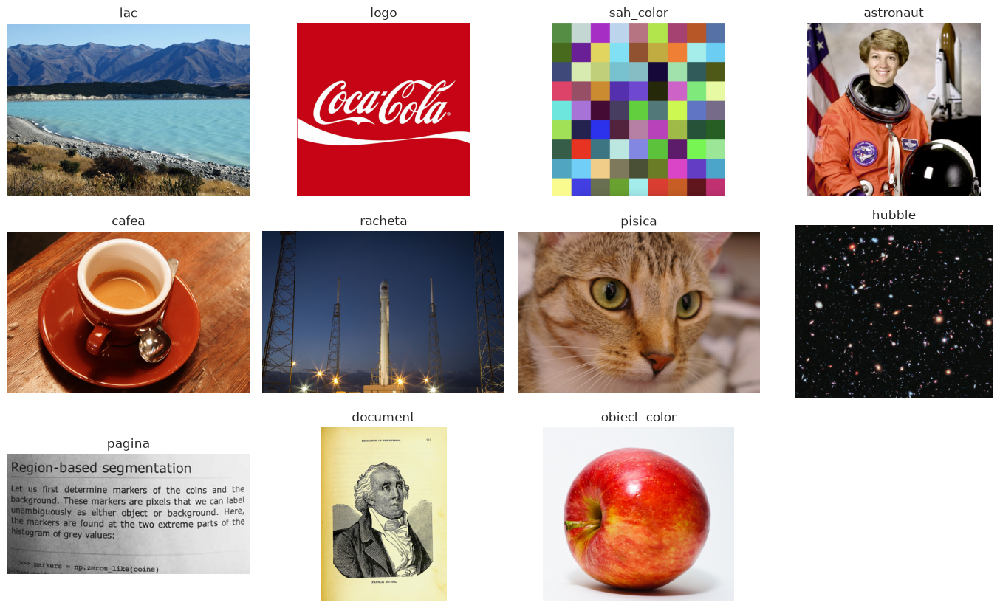

In [88]:
show(list(IMAGES.values()), list(IMAGES.keys()), cols=4, size=3.5)

### Histograme
Histograma (`cv2.calcHist`) arată distribuția intensităților pe fiecare canal. Pentru `lac` domină canalul albastru; pentru `pagina`
(document cu iluminare neuniformă) histograma e bimodală — text (întunecat) și hârtie (luminoasă) — dar cu suprapunere.

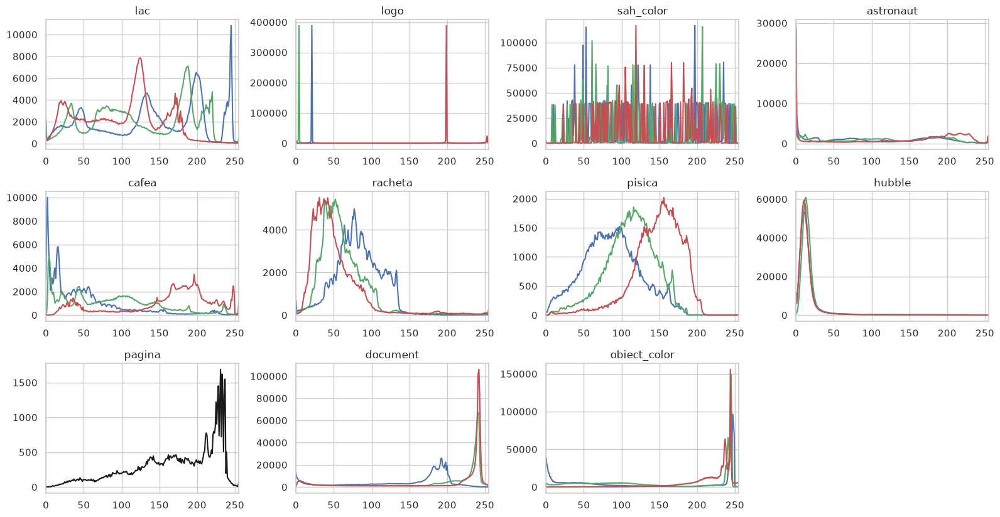

In [89]:
def plot_hist(img, ax, title):
    channels = [(0, 'k')] if img.ndim == 2 else [(0, 'b'), (1, 'g'), (2, 'r')]
    for c, color in channels:
        ax.plot(cv2.calcHist([img], [c], None, [256], [0, 256]), color=color)
    ax.set_title(title)
    ax.set_xlim(0, 255)

names = list(IMAGES)
cols = 4
rows_n = int(np.ceil(len(names) / cols))
fig, axes = plt.subplots(rows_n, cols, figsize=(4 * cols, 2.8 * rows_n))
axes = np.atleast_1d(axes).ravel()
for ax, name in zip(axes, names):
    plot_hist(IMAGES[name], ax, name)
for ax in axes[len(names):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

## 1. Transformări geometrice
- **Decupare**: indexare NumPy `img[y1:y2, x1:x2]` (fără copiere — este un *view*);
- **Flip**: `cv2.flip` — orizontal (`1`), vertical (`0`), ambele (`-1`);
- **Rotire**: matrice afină `cv2.getRotationMatrix2D` aplicată cu `cv2.warpAffine`;
- **Redimensionare**: `cv2.resize` (după factor sau dimensiune fixă).

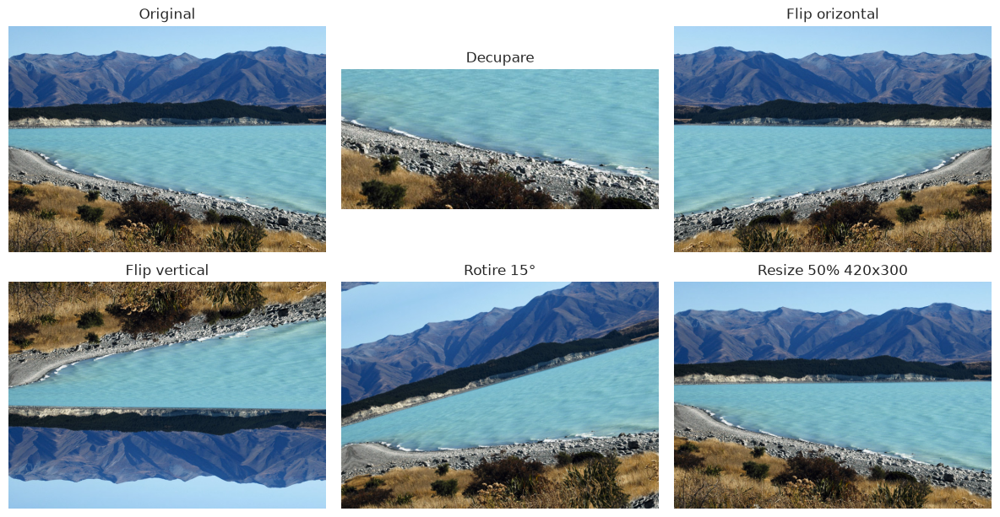

In [90]:
img = IMAGES['lac']
h, w = img.shape[:2]

crop = img[300:520, 150:650]
flip_h = cv2.flip(img, 1)
flip_v = cv2.flip(img, 0)
M = cv2.getRotationMatrix2D(center=(w / 2, h / 2), angle=15, scale=1.0)
rot = cv2.warpAffine(img, M, (w, h), borderMode=cv2.BORDER_REFLECT)
half = cv2.resize(img, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)

show([img, crop, flip_h, flip_v, rot, half],
     ['Original', 'Decupare', 'Flip orizontal', 'Flip vertical', 'Rotire 15°', f'Resize 50% {half.shape[1]}x{half.shape[0]}'],
     cols=3)

### Comparația metodelor de interpolare
Alegerea interpolării depinde de direcție. Le comparăm obiectiv, separat pe două roluri:
- **micșorare**: reducem la 25% cu metoda testată, apoi mărim înapoi cu o metodă fixă de calitate (`LANCZOS4`);
- **mărire**: reducem la 25% cu metoda fixă recomandată (`AREA`), apoi mărim înapoi cu metoda testată.

Măsurăm timpul pasului testat și calitatea reconstrucției față de original:
**PSNR** (dB, mai mare = mai fidel) și **SSIM** (în `[0, 1]`, mai aproape de 1 = structură mai bine păstrată).

In [91]:
INTERP = {
    'NEAREST': cv2.INTER_NEAREST,
    'LINEAR': cv2.INTER_LINEAR,
    'AREA': cv2.INTER_AREA,
    'CUBIC': cv2.INTER_CUBIC,
    'LANCZOS4': cv2.INTER_LANCZOS4,
}
SCALE = 0.25

def shrink(img, interp):
    return cv2.resize(img, None, fx=SCALE, fy=SCALE, interpolation=interp)

def enlarge(small, img, interp):
    return cv2.resize(small, (img.shape[1], img.shape[0]), interpolation=interp)

def quality(img, rec):
    return {
        'psnr': peak_signal_noise_ratio(img, rec, data_range=255),
        'ssim': structural_similarity(img, rec, channel_axis=2, data_range=255),
    }

test_names = ['lac', 'astronaut', 'cafea', 'racheta', 'pisica'] + [n for n in ['peisaj'] if n in IMAGES]
rows = []
for name in test_names:
    img = IMAGES[name]
    small_area = shrink(img, cv2.INTER_AREA)
    for label, interp in INTERP.items():
        # rolul "micsorare": metoda testată la micșorare, LANCZOS4 la mărire
        ms = timeit_ms(lambda: shrink(img, interp))
        rec = enlarge(shrink(img, interp), img, cv2.INTER_LANCZOS4)
        rows.append({'imagine': name, 'metoda': label, 'rol': 'micsorare', 'timp_ms': ms, **quality(img, rec)})
        # rolul "marire": AREA la micșorare, metoda testată la mărire
        ms = timeit_ms(lambda: enlarge(small_area, img, interp))
        rec = enlarge(small_area, img, interp)
        rows.append({'imagine': name, 'metoda': label, 'rol': 'marire', 'timp_ms': ms, **quality(img, rec)})

interp_df = pd.DataFrame(rows)
save_json(interp_df, 'interpolare.json')
interp_df.head(10)

Salvat: rezultate/interpolare.json


,imagine,metoda,rol,timp_ms,psnr,ssim
0,lac,NEAREST,micsorare,0.037128,20.321436,0.599691
1,lac,NEAREST,marire,0.243774,23.017544,0.695885
2,lac,LINEAR,micsorare,0.091552,22.556678,0.698059
3,lac,LINEAR,marire,0.266835,23.174641,0.687162
4,lac,AREA,micsorare,0.637626,23.483649,0.711379
5,lac,AREA,marire,0.261772,23.017544,0.695885
6,lac,CUBIC,micsorare,0.133026,21.668194,0.678056
7,lac,CUBIC,marire,0.616121,23.477897,0.710635
8,lac,LANCZOS4,micsorare,1.652111,21.525828,0.673590
9,lac,LANCZOS4,marire,3.654347,23.483649,0.711379


Comparație vizuală la mărire pe o regiune cu detalii fine (blana pisicii): `NEAREST` produce blocuri, `LINEAR` netezește, `CUBIC`/`LANCZOS4` păstrează mai bine muchiile.

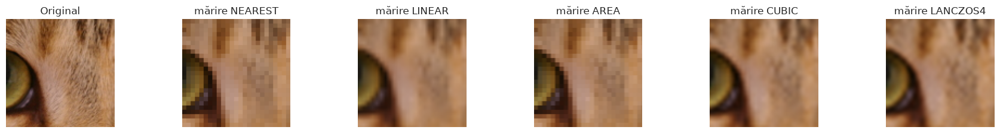

In [51]:
img = IMAGES['pisica']
small_area = shrink(img, cv2.INTER_AREA)
y, x = 60, 180
crops = [img[y:y + 100, x:x + 100]]
crops += [enlarge(small_area, img, i)[y:y + 100, x:x + 100] for i in INTERP.values()]
show(crops, ['Original'] + [f'mărire {k}' for k in INTERP], cols=6, size=3)

In [52]:
interp_agg = interp_df.groupby(['rol', 'metoda']).agg(
    timp_ms=('timp_ms', 'mean'),
    psnr=('psnr', 'mean'),
    ssim=('ssim', 'mean'),
).round(3)
interp_agg.unstack('rol')

timp_ms              psnr             ssim          
rol       marire micsorare  marire micsorare marire micsorare
metoda                                                       
AREA       0.175     0.364  25.317    26.453  0.755     0.786
CUBIC      0.434     0.084  26.413    24.799  0.785     0.759
LANCZOS4   2.072     0.947  26.453    24.668  0.786     0.755
LINEAR     0.175     0.054  25.885    25.634  0.764     0.775
NEAREST    0.164     0.022  25.329    22.789  0.756     0.681

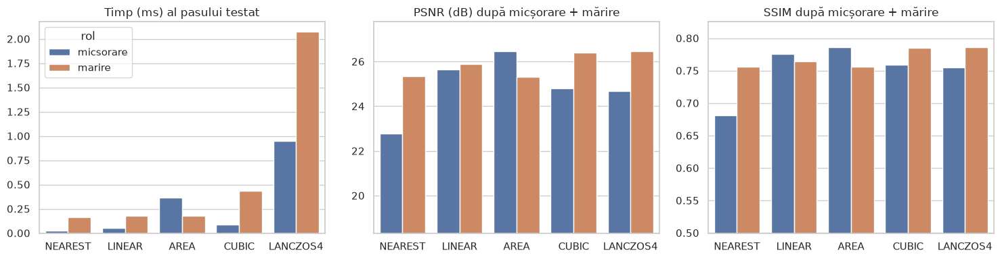

In [53]:
titles = ['Timp (ms) al pasului testat', 'PSNR (dB) după micșorare + mărire', 'SSIM după micșorare + mărire']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric, title in zip(axes, ['timp_ms', 'psnr', 'ssim'], titles):
    sns.barplot(data=interp_df, x='metoda', y=metric, hue='rol', ax=ax,
                errorbar=None, legend=(metric == 'timp_ms'))
    ax.set_title(title); ax.set_xlabel(''); ax.set_ylabel('')
axes[1].set_ylim(interp_df.psnr.min() - 2, None)
axes[2].set_ylim(max(0, interp_df.ssim.min() - 0.1), None)
plt.tight_layout()
plt.show()

## 2. Luminozitate, contrast și gamma
Imaginile sunt `uint8`, deci aritmetica poate depăși `[0, 255]`. NumPy face **wrap-around** (`250 + 100 = 94`),
iar `cv2.add`/`cv2.subtract` **saturează** (`250 + 100 = 255`). Comparația arată de ce overflow-ul trebuie tratat explicit.

NumPy  250 + 100 = 94  (wrap-around)
OpenCV 250 + 100 = 255  (saturare)
cv2.add identic cu np.clip: True


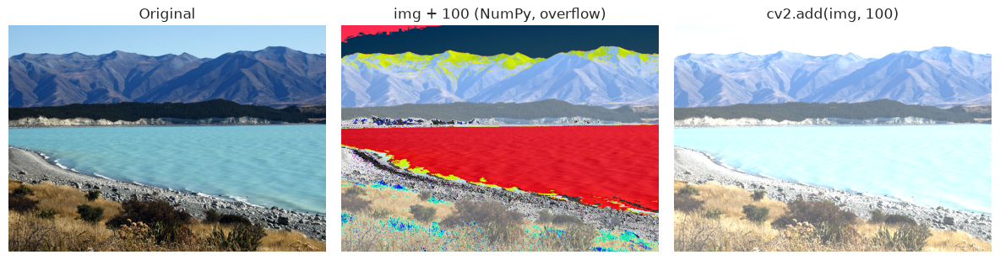

In [54]:
a, b = np.full((1, 1), 250, np.uint8), np.full((1, 1), 100, np.uint8)
print('NumPy  250 + 100 =', (a + b)[0, 0], ' (wrap-around)')
print('OpenCV 250 + 100 =', cv2.add(a, b)[0, 0], ' (saturare)')

img = IMAGES['lac']
plus_np = img + np.uint8(100)                                     # overflow: wrap-around
plus_cv = cv2.add(img, np.full_like(img, 100))                    # saturare la 255
plus_clip = np.clip(img.astype(np.int16) + 100, 0, 255).astype(np.uint8)
print('cv2.add identic cu np.clip:', np.array_equal(plus_cv, plus_clip))

show([img, plus_np, plus_cv], ['Original', 'img + 100 (NumPy, overflow)', 'cv2.add(img, 100)'], cols=3)

**Contrast și luminozitate** — transformare liniară `out = α·in + β` cu `cv2.convertScaleAbs` (înmulțire, adunare, saturare într-un pas).  
**Gamma** — neliniară, `out = 255·(in/255)^γ`, aplicată eficient printr-un tabel de căutare (`cv2.LUT`): γ < 1 luminează tonurile întunecate, γ > 1 le întunecă.

Pentru fiecare variantă măsurăm **media** (luminozitate), **deviația standard** (contrast) și **procentul de pixeli saturați** (0 sau 255) — informație pierdută ireversibil.

In [55]:
def gamma_correct(img, gamma):
    lut = np.clip(255 * (np.arange(256) / 255.0) ** gamma + 0.5, 0, 255).astype(np.uint8)
    return cv2.LUT(img, lut)

def intensity_stats(img):
    saturated = np.mean((img == 0) | (img == 255))
    return {
        'medie': round(float(img.mean()), 1),
        'std': round(float(img.std()), 1),
        'saturati_%': round(100 * float(saturated), 2),
    }

def add_const(img, v):
    return cv2.add(img, np.full_like(img, v))

def sub_const(img, v):
    return cv2.subtract(img, np.full_like(img, v))

variants = {
    'original': img,
    'luminos (+60)': add_const(img, 60),
    'intunecat (-60)': sub_const(img, 60),
    'contrast x1.6': cv2.convertScaleAbs(img, alpha=1.6, beta=0),
    'contrast x0.6': cv2.convertScaleAbs(img, alpha=0.6, beta=0),
    'contrast x1.6 -80': cv2.convertScaleAbs(img, alpha=1.6, beta=-80),
    'gamma 0.5': gamma_correct(img, 0.5),
    'gamma 2.0': gamma_correct(img, 2.0),
}
bc_df = pd.DataFrame([{'varianta': k, **intensity_stats(v)} for k, v in variants.items()])
save_json(bc_df, 'luminozitate_contrast.json')
bc_df

Salvat: rezultate/luminozitate_contrast.json


,varianta,medie,std,saturati_%
0,original,122.6,64.6,0.28
1,luminos (+60),179.2,59.6,15.76
2,intunecat (-60),68.4,56.6,21.73
3,contrast x1.6,176.3,79.3,33.41
4,contrast x0.6,73.5,38.8,0.22
5,contrast x1.6 -80,125.7,82.7,8.49
6,gamma 0.5,168.8,52.6,0.28
7,gamma 2.0,75.3,63.9,1.73


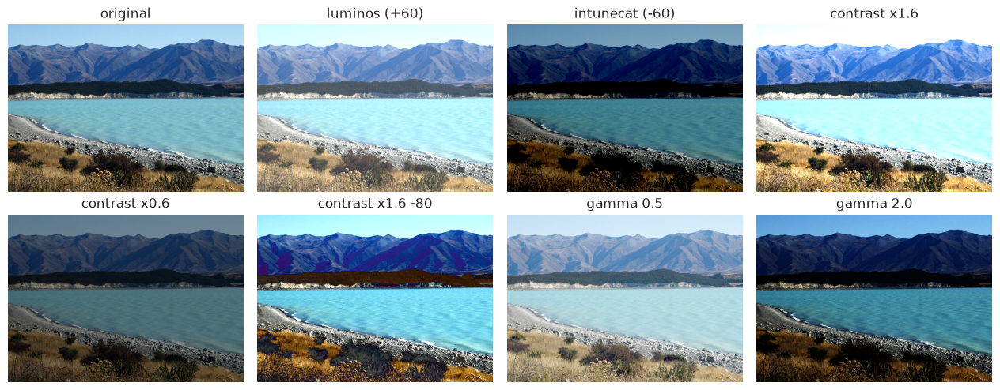

In [56]:
show(list(variants.values()), list(variants.keys()), cols=4, size=3.2)

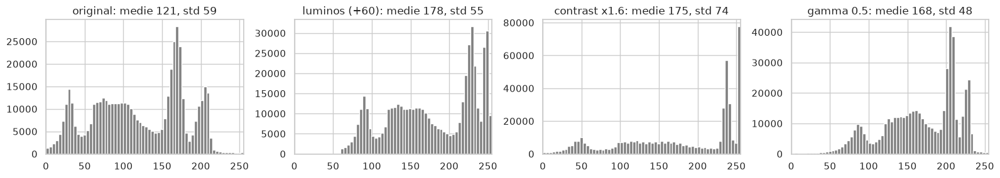

In [57]:
selected = ['original', 'luminos (+60)', 'contrast x1.6', 'gamma 0.5']
fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for ax, key in zip(axes, selected):
    gray = cv2.cvtColor(variants[key], cv2.COLOR_BGR2GRAY)
    ax.hist(gray.ravel(), bins=64, range=(0, 255), color='gray')
    ax.set_title(f'{key}: medie {gray.mean():.0f}, std {gray.std():.0f}')
    ax.set_xlim(0, 255)
plt.tight_layout()
plt.show()

### Scenă slab iluminată (imagine proprie)
Aplicăm aceleași operații pe scena întunecată proprie (`scena_intunecata`). Dacă lipsește, o simulăm întunecând `lac` (α = 0.3).
Comparăm o întărire liniară (care saturează luminile) cu corecția gamma (care ridică doar tonurile întunecate).

scena_intunecata lipsește -> folosesc lac întunecat artificial
Salvat: rezultate/scena_intunecata.json


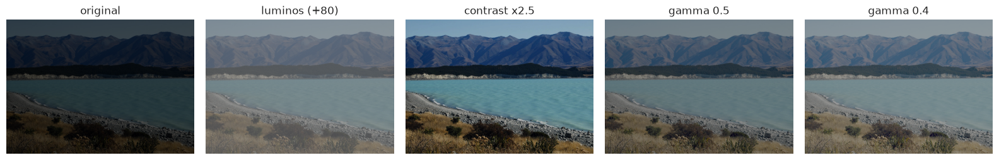

,varianta,medie,std,saturati_%
0,original,36.8,19.4,0.29
1,luminos (+80),116.8,19.4,0.00
2,contrast x2.5,92.0,48.5,0.29
3,gamma 0.5,92.4,28.8,0.29
4,gamma 0.4,112.3,29.2,0.29


In [58]:
dark = IMAGES.get('scena_intunecata')
if dark is None:
    print('scena_intunecata lipsește -> folosesc lac întunecat artificial')
    dark = cv2.convertScaleAbs(IMAGES['lac'], alpha=0.3)
if dark.ndim == 2:
    dark = cv2.cvtColor(dark, cv2.COLOR_GRAY2BGR)

dark_variants = {
    'original': dark,
    'luminos (+80)': add_const(dark, 80),
    'contrast x2.5': cv2.convertScaleAbs(dark, alpha=2.5, beta=0),
    'gamma 0.5': gamma_correct(dark, 0.5),
    'gamma 0.4': gamma_correct(dark, 0.4),
}
dark_df = pd.DataFrame([{'varianta': k, **intensity_stats(v)} for k, v in dark_variants.items()])
save_json(dark_df, 'scena_intunecata.json')
show(list(dark_variants.values()), list(dark_variants.keys()), cols=5, size=3.2)
dark_df

## 3. Spații de culori
`cv2.cvtColor` convertește între spații; `cv2.split` / `cv2.merge` separă și îmbină canalele.
- **Gray**: o singură intensitate (`0.299R + 0.587G + 0.114B`);
- **HSV**: nuanță (H ∈ [0, 179] în OpenCV), saturație, valoare;
- **LAB**: L = luminozitate, A = verde↔roșu, B = albastru↔galben;
- **YCrCb**: Y = luminanță, Cr/Cb = crominanță (roșu / albastru).

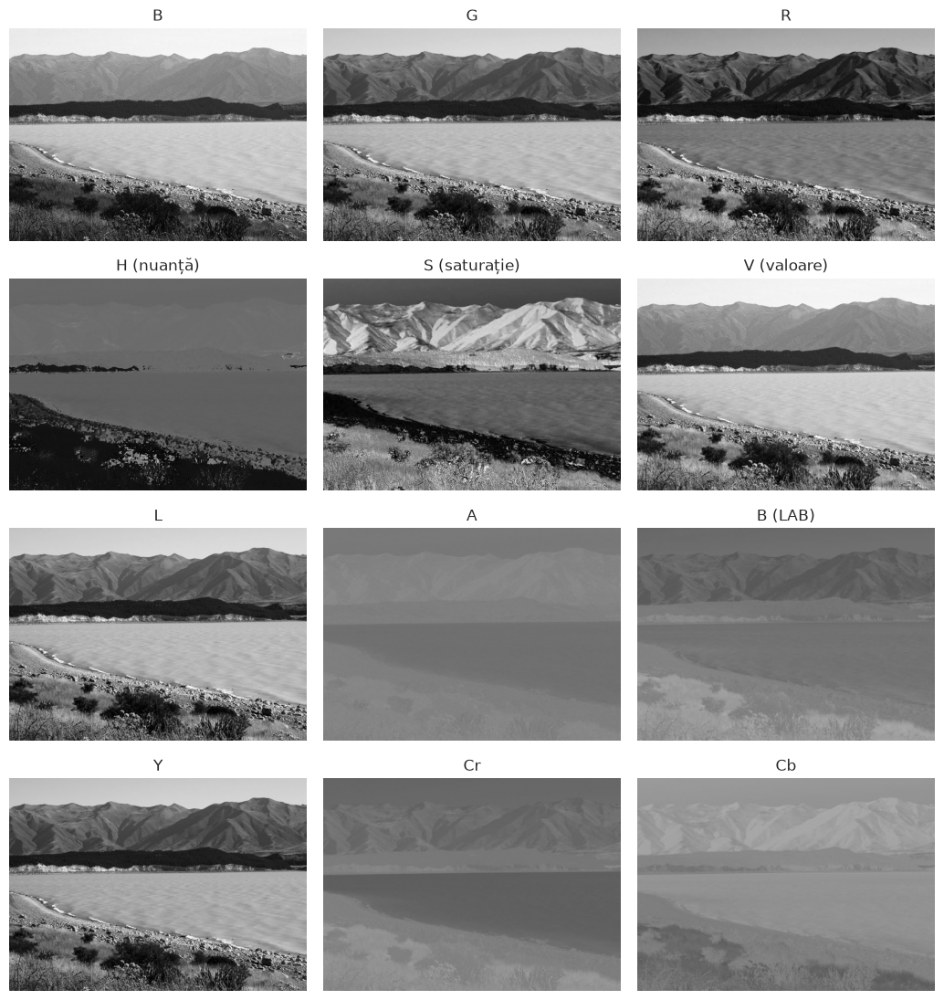

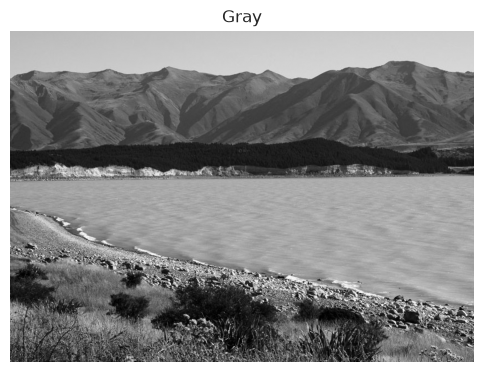

In [102]:
img = IMAGES['lac']
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
ycrcb = cv2.cvtColor(img, cv2.COLOR_BGR2YCrCb)

b, g, r = cv2.split(img)
hh, ss, vv = cv2.split(hsv)
L, A, B = cv2.split(lab)
Y, Cr, Cb = cv2.split(ycrcb)

show([b, g, r, hh, ss, vv, L, A, B, Y, Cr, Cb],
     ['B', 'G', 'R', 'H (nuanță)', 'S (saturație)', 'V (valoare)',
      'L', 'A', 'B (LAB)', 'Y', 'Cr', 'Cb'], cols=3, size=3.5)
show([gray], ['Gray'], size=5)

**Îmbinarea canalelor**: `cv2.merge` pe canalele originale reface exact imaginea; schimbând ordinea canalelor obținem culori false.
Modificând un singur canal după `split` schimbăm aspectul: rotim nuanța cu 60° (+30 în OpenCV, ciclic modulo 180) și creștem saturația.

merge(split(img)) == img: True


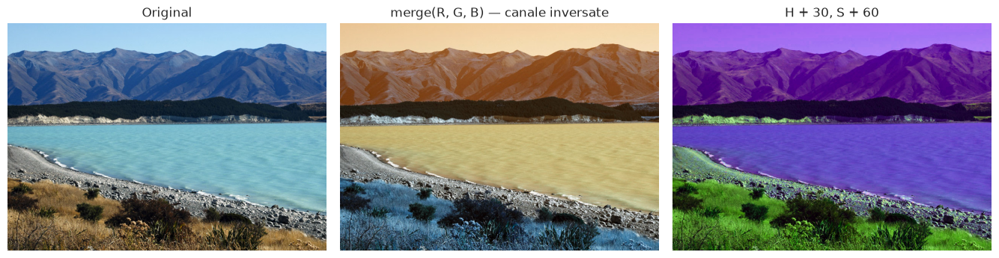

In [103]:
print('merge(split(img)) == img:', np.array_equal(cv2.merge((b, g, r)), img))
swapped = cv2.merge((r, g, b))                                   # R și B inversate

h_new = ((hh.astype(np.int16) + 30) % 180).astype(np.uint8)      # rotire ciclică a nuanței
hsv_mod = cv2.merge((h_new, add_const(ss, 60), vv))
img_mod = cv2.cvtColor(hsv_mod, cv2.COLOR_HSV2BGR)

show([img, swapped, img_mod], ['Original', 'merge(R, G, B) — canale inversate', 'H + 30, S + 60'], cols=3, size=4.5)

### Segmentare după culoare: RGB vs HSV
Segmentăm apa turcoaz a lacului. În HSV culoarea e descrisă de un interval de nuanță și saturație, în mare măsură independent de luminozitate;
`cv2.inRange` produce direct o mască binară. Explorați intervalele interactiv:

In [104]:
@interact(h_min=(0, 179, 1), h_max=(0, 179, 1), s_min=(0, 255, 5), v_min=(0, 255, 5))
def explore_hsv(h_min=80, h_max=100, s_min=60, v_min=80):
    mask = cv2.inRange(hsv, (h_min, s_min, v_min), (h_max, 255, 255))
    segmented = cv2.bitwise_and(img, img, mask=mask)
    title = f'Mască H[{h_min}, {h_max}], S≥{s_min}, V≥{v_min}'
    show([mask, segmented], [title, 'Segmentare'], cols=2, size=4.5)

interactive(children=(IntSlider(value=80, description='h_min', max=179), IntSlider(value=100, description='h_m…

Pentru a compara stabilitatea la iluminare avem nevoie de o **mască de referință** (rolul unei adnotări manuale): masca HSV curățată prin
morfologie (`cv2.morphologyEx`: *deschiderea* elimină punctele izolate, *închiderea* umple golurile mici) și redusă la componenta cea mai mare.
Apoi calibrăm ambele metode pe aceiași pixeli de referință, folosind percentilele 2–98:
- **RGB**: un paralelipiped de praguri pe B, G și R;
- **HSV**: praguri pe H și S; pe V doar un prag minim (exclude pixelii aproape negri, unde nuanța e nedefinită).

Masca de referință acoperă 25.2% din imagine
Praguri BGR: [162. 150. 103.] - [212. 197. 141.]
Praguri HSV: [92. 68. 30.] - [ 99. 255. 255.]


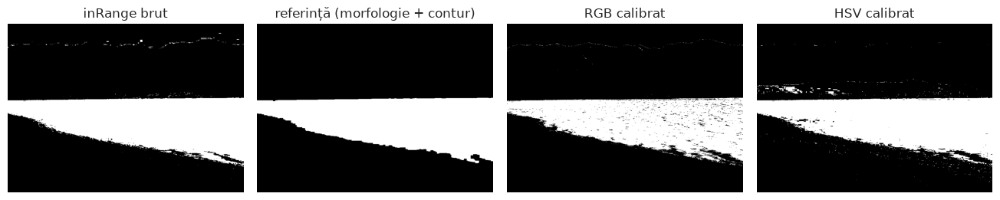

In [62]:
KERNEL = np.ones((7, 7), np.uint8)

raw_mask = cv2.inRange(hsv, (80, 60, 80), (100, 255, 255))
clean = cv2.morphologyEx(raw_mask, cv2.MORPH_OPEN, KERNEL)
clean = cv2.morphologyEx(clean, cv2.MORPH_CLOSE, KERNEL)
contours, _ = cv2.findContours(clean, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
largest = max(contours, key=cv2.contourArea)

ref_mask = np.zeros_like(raw_mask)
cv2.drawContours(ref_mask, [largest], -1, 255, -1)
print(f'Masca de referință acoperă {100 * ref_mask.mean() / 255:.1f}% din imagine')

px_bgr = img[ref_mask > 0]
px_hsv = hsv[ref_mask > 0]

lo_bgr = tuple(float(v) for v in np.percentile(px_bgr, 2, axis=0))
hi_bgr = tuple(float(v) for v in np.percentile(px_bgr, 98, axis=0))
h_lo, h_hi = np.percentile(px_hsv[:, 0], [2, 98])
s_lo = np.percentile(px_hsv[:, 1], 2)
lo_hsv, hi_hsv = (float(h_lo), float(s_lo), 30.0), (float(h_hi), 255.0, 255.0)
print('Praguri BGR:', np.round(lo_bgr), '-', np.round(hi_bgr))
print('Praguri HSV:', np.round(lo_hsv), '-', np.round(hi_hsv))

def segment_rgb(bgr):
    return cv2.inRange(bgr, lo_bgr, hi_bgr)

def segment_hsv(bgr):
    return cv2.inRange(cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV), lo_hsv, hi_hsv)

def iou(mask_a, mask_b):
    a, b = mask_a > 0, mask_b > 0
    union = (a | b).sum()
    return (a & b).sum() / union if union else 1.0

show([raw_mask, ref_mask, segment_rgb(img), segment_hsv(img)],
     ['inRange brut', 'referință (morfologie + contur)', 'RGB calibrat', 'HSV calibrat'], cols=4, size=3.3)

Simulăm schimbări de iluminare (gamma, scalarea luminozității, supraexpunere, lumină caldă/rece) și măsurăm pe pixelii de referință:
cât se schimbă fiecare canal (diferența medie absolută în BGR și HSV) și **IoU** (Intersection over Union) dintre masca obținută și masca de referință.

In [63]:
def scale_channels(bgr, factors):
    scaled = bgr.astype(np.float32) * np.array(factors, np.float32)
    return np.clip(scaled, 0, 255).astype(np.uint8)

def channel_shift(original, changed, mask):
    o_hsv = cv2.cvtColor(original, cv2.COLOR_BGR2HSV)
    c_hsv = cv2.cvtColor(changed, cv2.COLOR_BGR2HSV)
    d_bgr = np.abs(original[mask > 0].astype(int) - changed[mask > 0].astype(int))
    d_hsv = np.abs(o_hsv[mask > 0].astype(int) - c_hsv[mask > 0].astype(int))
    deltas = np.concatenate([d_bgr.mean(axis=0), d_hsv.mean(axis=0)])
    return dict(zip(['dB', 'dG', 'dR', 'dH', 'dS', 'dV'], deltas.round(1)))

ILLUMINATION = {
    'original': lambda im: im,
    'gamma 0.6': lambda im: gamma_correct(im, 0.6),
    'gamma 0.8': lambda im: gamma_correct(im, 0.8),
    'gamma 1.25': lambda im: gamma_correct(im, 1.25),
    'gamma 1.6': lambda im: gamma_correct(im, 1.6),
    'gamma 2.0': lambda im: gamma_correct(im, 2.0),
    'luminozitate x0.5': lambda im: scale_channels(im, (0.5, 0.5, 0.5)),
    'luminozitate x0.75': lambda im: scale_channels(im, (0.75, 0.75, 0.75)),
    'luminozitate x1.2': lambda im: scale_channels(im, (1.2, 1.2, 1.2)),
    'supraexpunere x1.4': lambda im: scale_channels(im, (1.4, 1.4, 1.4)),
    'lumina calda 8%': lambda im: scale_channels(im, (0.92, 1.0, 1.08)),
    'lumina rece 8%': lambda im: scale_channels(im, (1.08, 1.0, 0.92)),
}

rows, masks = [], {}
for label, transform in ILLUMINATION.items():
    changed = transform(img)
    m_rgb, m_hsv = segment_rgb(changed), segment_hsv(changed)
    masks[label] = (changed, m_rgb, m_hsv)
    row = {'iluminare': label, **channel_shift(img, changed, ref_mask)}
    row['IoU_RGB'] = round(float(iou(m_rgb, ref_mask)), 3)
    row['IoU_HSV'] = round(float(iou(m_hsv, ref_mask)), 3)
    rows.append(row)

color_df = pd.DataFrame(rows)
save_json(color_df, 'segmentare_culoare.json')
color_df

Salvat: rezultate/segmentare_culoare.json


,iluminare,dB,dG,dR,dH,dS,dV,IoU_RGB,IoU_HSV
0,original,0.0,0.0,0.0,0.0,0.0,0.0,0.922,0.944
1,gamma 0.6,21.6,26.1,41.5,0.5,32.7,21.6,0.007,0.197
2,gamma 0.8,10.5,12.6,19.3,0.3,15.6,10.5,0.407,0.885
3,gamma 1.25,12.4,14.6,20.4,0.2,17.5,12.4,0.522,0.954
4,gamma 1.6,28.4,33.0,43.5,0.5,39.0,28.4,0.010,0.944
5,gamma 2.0,44.8,51.5,63.5,1.0,59.5,44.8,0.000,0.929
6,luminozitate x0.5,98.2,91.3,61.7,0.3,0.7,98.2,0.000,0.958
7,luminozitate x0.75,49.4,45.9,31.1,0.2,0.5,49.4,0.001,0.951
8,luminozitate x1.2,38.8,36.0,24.2,0.1,0.3,38.8,0.039,0.904
9,supraexpunere x1.4,57.4,67.3,48.7,4.3,12.8,57.4,0.006,0.281


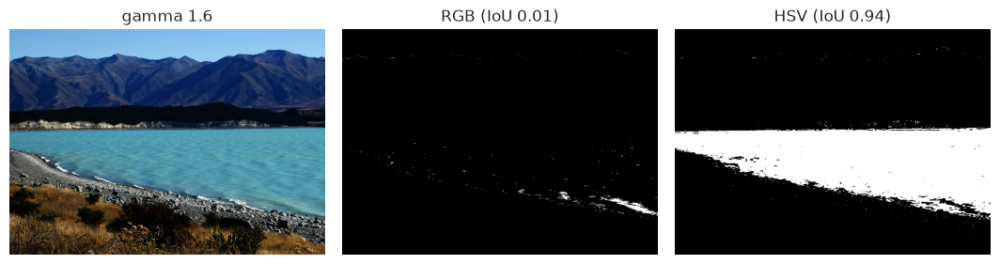

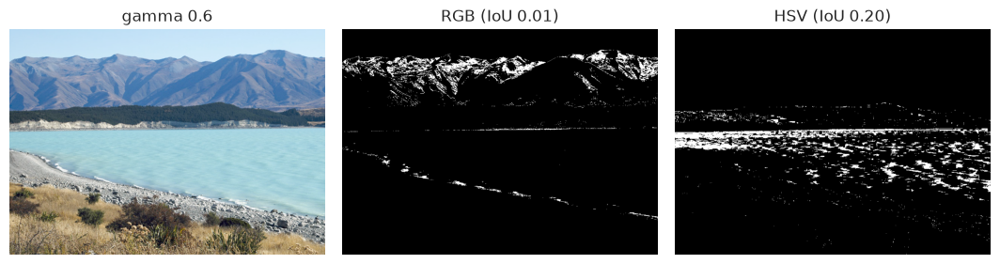

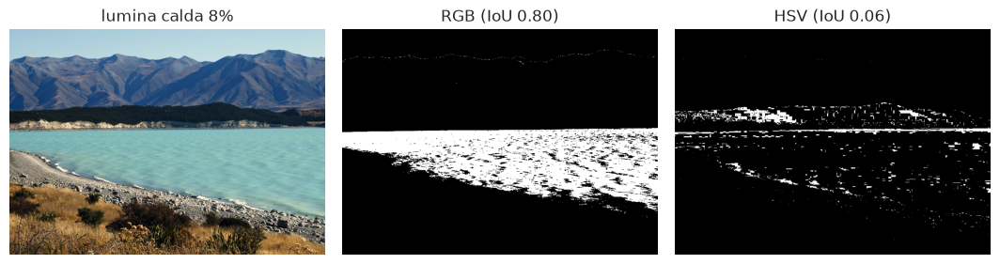

In [64]:
for label in ['gamma 1.6', 'gamma 0.6', 'lumina calda 8%']:
    changed, m_rgb, m_hsv = masks[label]
    show([changed, m_rgb, m_hsv],
         [label, f'RGB (IoU {iou(m_rgb, ref_mask):.2f})', f'HSV (IoU {iou(m_hsv, ref_mask):.2f})'],
         cols=3, size=3.6)

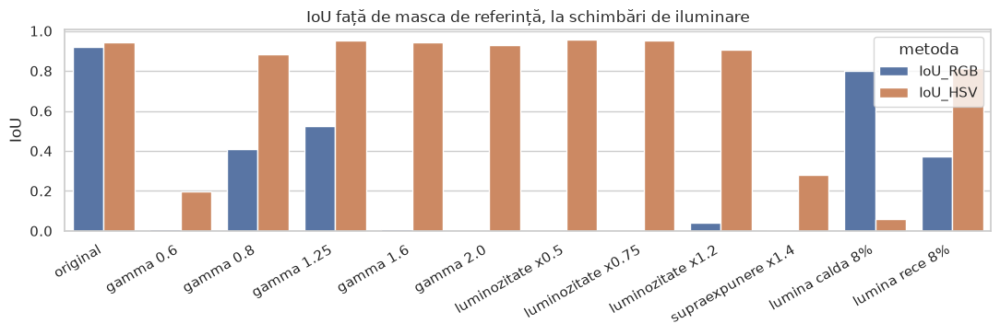

In [65]:
long_df = color_df.melt(id_vars='iluminare', value_vars=['IoU_RGB', 'IoU_HSV'], var_name='metoda', value_name='IoU')
plt.figure(figsize=(11, 3.8))
sns.barplot(data=long_df, x='iluminare', y='IoU', hue='metoda')
plt.xticks(rotation=30, ha='right'); plt.xlabel('')
plt.title('IoU față de masca de referință, la schimbări de iluminare')
plt.tight_layout()
plt.show()

### Obiect cu culoare distinctă
Aplicați segmentarea HSV pe `obiect_color`. Ajustați `OBJ_LO` / `OBJ_HI` după nuanța obiectului
(orientativ, în OpenCV: roșu ≈ 0–10 și 170–179, galben ≈ 20–35, verde ≈ 35–85, albastru ≈ 95–130).

Obiectul acoperă 89.3% din imagine


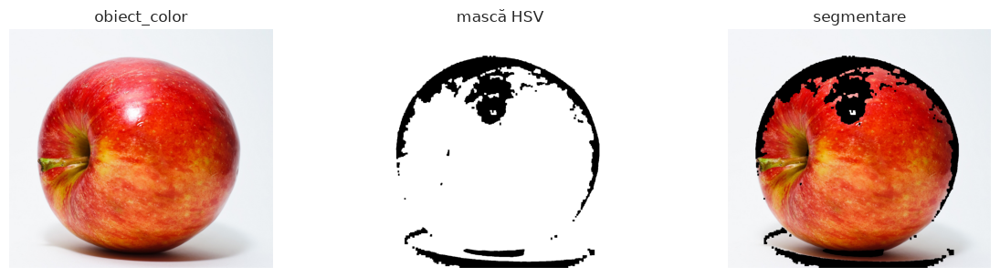

In [69]:
OBJ_LO, OBJ_HI = (0, 0, 50), (130, 255, 255)     # <- ajustați pentru obiectul vostru

if 'obiect_color' in IMAGES:
    obj = IMAGES['obiect_color']
    obj_mask = cv2.inRange(cv2.cvtColor(obj, cv2.COLOR_BGR2HSV), OBJ_LO, OBJ_HI)
    obj_mask = cv2.morphologyEx(obj_mask, cv2.MORPH_OPEN, KERNEL)
    obj_mask = cv2.morphologyEx(obj_mask, cv2.MORPH_CLOSE, KERNEL)
    print(f'Obiectul acoperă {100 * obj_mask.mean() / 255:.1f}% din imagine')
    show([obj, obj_mask, cv2.bitwise_and(obj, obj, mask=obj_mask)],
         ['obiect_color', 'mască HSV', 'segmentare'], cols=3, size=4)
else:
    print('obiect_color lipsește din', IMG_DIR)

## 4. Praguri și măști
Binarizarea unui document fotografiat este primul pas în OCR. Comparăm pe `pagina` (iluminare puternic neuniformă):
- **prag global** (`cv2.threshold`, T fix = 127);
- **Otsu** (T ales automat, minimizând varianța intra-clasă din histogramă);
- **adaptiv** (`cv2.adaptiveThreshold`, T calculat local dintr-o vecinătate — medie sau medie ponderată gaussian).

Prag Otsu: 157.0


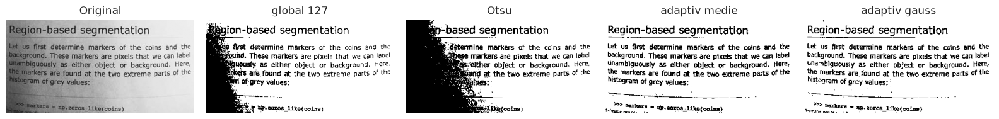

In [70]:
def global_threshold(im, t=127):
    return cv2.threshold(im, t, 255, cv2.THRESH_BINARY)[1]

def otsu_threshold(im):
    return cv2.threshold(im, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)[1]

def adaptive_threshold(im, method, block=31, c=12):
    return cv2.adaptiveThreshold(im, 255, method, cv2.THRESH_BINARY, block, c)

MEAN, GAUSS = cv2.ADAPTIVE_THRESH_MEAN_C, cv2.ADAPTIVE_THRESH_GAUSSIAN_C
METHODS = {
    'global 127': global_threshold,
    'Otsu': otsu_threshold,
    'adaptiv medie': lambda im: adaptive_threshold(im, MEAN),
    'adaptiv gauss': lambda im: adaptive_threshold(im, GAUSS),
}

page = IMAGES['pagina']
otsu_t, _ = cv2.threshold(page, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
print('Prag Otsu:', otsu_t)
show([page] + [m(page) for m in METHODS.values()], ['Original'] + list(METHODS), cols=5, size=3.2)

Vizual câștigă pragul adaptiv, dar pentru o evaluare **numerică** avem nevoie de adevărul de bază (care pixeli sunt text). Îl obținem cu un
**document sintetic**: randăm text cu `cv2.putText` (masca de text e cunoscută exact), apoi îl degradăm cu un gradient de iluminare de intensitate
controlată și zgomot gaussian. Zgomotul e redus cu un filtru median 3×3 înainte de binarizare (același pas pentru toate metodele).
Măsurăm **F1** pe pixelii de text: `F1 = 2TP / (2TP + FP + FN)`.

In [71]:
LINES = ['Vederea computerizata', 'OpenCV + NumPy', 'Praguri: global, Otsu, adaptiv',
         'Lucrare de laborator 1', 'F1 = 2PR / (P + R)']

def synthetic_document(size=(360, 640), text_val=60, paper_val=230):
    doc = np.full(size, paper_val, np.uint8)
    for i, text in enumerate(LINES):
        cv2.putText(doc, text, (25, 60 + i * 65), cv2.FONT_HERSHEY_SIMPLEX, 1.1, text_val, 2, cv2.LINE_AA)
    return cv2.GaussianBlur(doc, (3, 3), 0)          # margini ușor neclare, ca la o poză

def degrade(doc, gradient, noise=8, seed=0):
    h, w = doc.shape
    ramp = np.linspace(1.0, 1.0 - gradient, w, dtype=np.float32)   # iluminarea scade spre dreapta
    rng = np.random.default_rng(seed)
    out = doc.astype(np.float32) * ramp[None, :] + rng.normal(0, noise, doc.shape)
    return np.clip(out, 0, 255).astype(np.uint8)

def f1_score(pred_text, true_text):
    tp = np.sum(pred_text & true_text)
    fp = np.sum(pred_text & ~true_text)
    fn = np.sum(~pred_text & true_text)
    return 2 * tp / (2 * tp + fp + fn)

doc = synthetic_document()
true_text = doc < 145
rows = []
for gradient in [0.0, 0.2, 0.4, 0.6, 0.8]:
    degraded = cv2.medianBlur(degrade(doc, gradient), 3)
    for name, method in METHODS.items():
        f1 = f1_score(method(degraded) < 128, true_text)
        rows.append({'gradient': gradient, 'metoda': name, 'F1': round(float(f1), 3)})

thresh_df = pd.DataFrame(rows)
save_json(thresh_df, 'praguri.json')
thresh_df.pivot(index='gradient', columns='metoda', values='F1')[list(METHODS)]

Salvat: rezultate/praguri.json


metoda,global 127,Otsu,adaptiv medie,adaptiv gauss
gradient,,,,
0.0,0.947,0.959,0.933,0.957
0.2,0.966,0.967,0.935,0.957
0.4,0.964,0.264,0.937,0.958
0.6,0.331,0.231,0.939,0.958
0.8,0.230,0.219,0.942,0.958


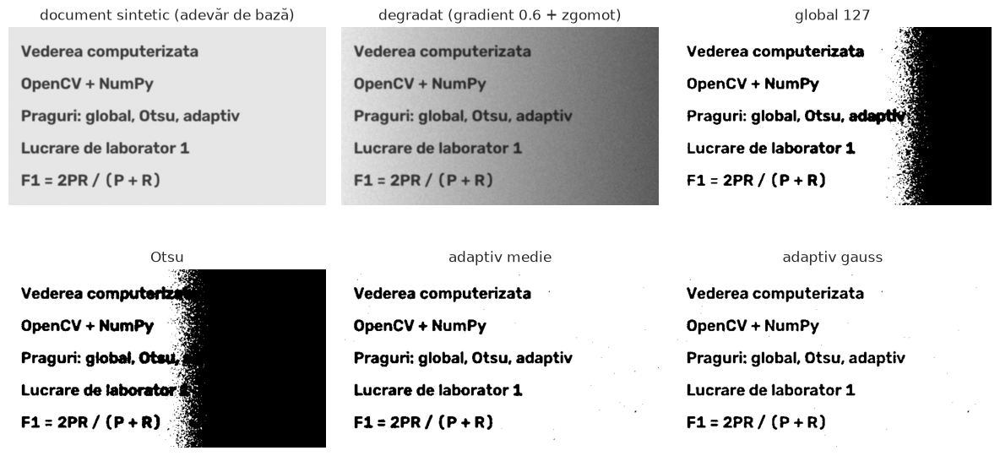

In [72]:
degraded = cv2.medianBlur(degrade(doc, 0.6), 3)
show([doc, degraded] + [m(degraded) for m in METHODS.values()],
     ['document sintetic (adevăr de bază)', 'degradat (gradient 0.6 + zgomot)'] + list(METHODS), cols=3, size=4)

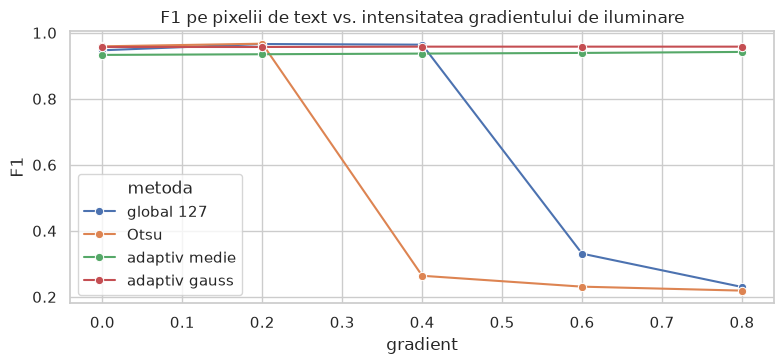

In [73]:
plt.figure(figsize=(8, 3.8))
sns.lineplot(data=thresh_df, x='gradient', y='F1', hue='metoda', marker='o')
plt.title('F1 pe pixelii de text vs. intensitatea gradientului de iluminare')
plt.tight_layout()
plt.show()

### Documentul propriu
Aplicăm aceleași metode pe documentul fotografiat propriu (`document`). Pentru poze mari, `block` poate fi mărit (ex. 51) — trebuie să fie impar.

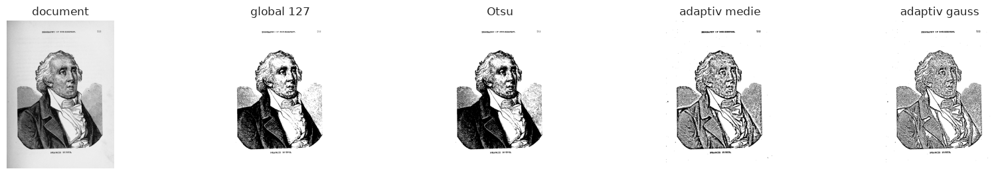

In [76]:
if 'document' in IMAGES:
    d = IMAGES['document']
    d = cv2.cvtColor(d, cv2.COLOR_BGR2GRAY) if d.ndim == 3 else d
    d = cv2.medianBlur(d, 3)
    show([d] + [m(d) for m in METHODS.values()], ['document'] + list(METHODS), cols=5, size=3.5)
else:
    print('document lipsește din', IMG_DIR)

### Măști și operații pe biți
O mască binară selectează pixelii pe care îi modificăm. Suprapunem literele logo-ului peste colțul lacului:
pragul pe logo-ul gri dă masca literelor; `cv2.bitwise_and` cu masca inversată „golește” fundalul, iar `cv2.add` combină prim-planul cu fundalul.
Comparativ, `cv2.addWeighted` amestecă două imagini cu ponderi (blending), fără mască.

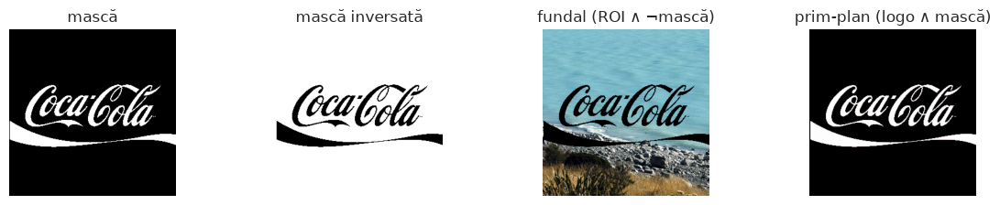

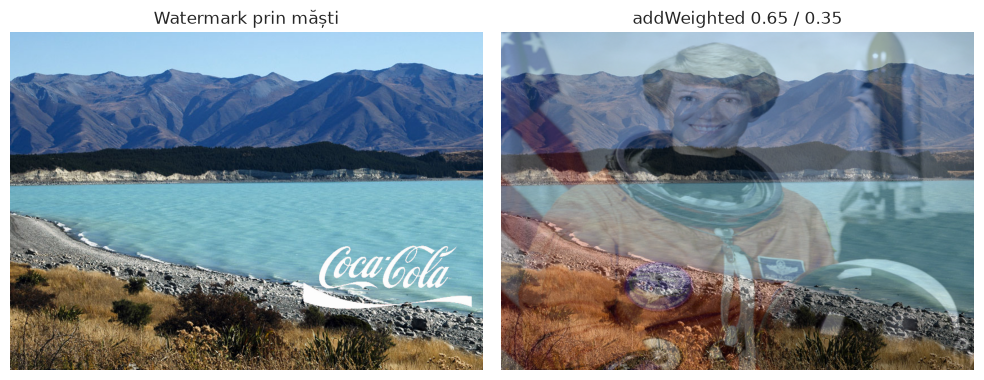

In [77]:
img = IMAGES['lac']
logo = cv2.resize(IMAGES['logo'], (300, 300), interpolation=cv2.INTER_AREA)

logo_gray = cv2.cvtColor(logo, cv2.COLOR_BGR2GRAY)
_, mask = cv2.threshold(logo_gray, 200, 255, cv2.THRESH_BINARY)   # literele albe
mask_inv = cv2.bitwise_not(mask)

lh, lw = mask.shape
roi = img[-lh - 20:-20, -lw - 20:-20]                             # colțul dreapta-jos
background = cv2.bitwise_and(roi, roi, mask=mask_inv)             # fundal fără litere
foreground = cv2.bitwise_and(logo, logo, mask=mask)               # doar literele

watermarked = img.copy()
watermarked[-lh - 20:-20, -lw - 20:-20] = cv2.add(background, foreground)

astro = cv2.resize(IMAGES['astronaut'], (img.shape[1], img.shape[0]))
blended = cv2.addWeighted(img, 0.65, astro, 0.35, 0)

show([mask, mask_inv, background, foreground],
     ['mască', 'mască inversată', 'fundal (ROI ∧ ¬mască)', 'prim-plan (logo ∧ mască)'], cols=4, size=3)
show([watermarked, blended], ['Watermark prin măști', 'addWeighted 0.65 / 0.35'], cols=2, size=5)

## 5. Adnotare și colaj
Adnotăm rezultatul segmentării: din masca apei extragem conturul (`cv2.findContours`), desenăm dreptunghiul de încadrare (`cv2.boundingRect`),
centrul de masă (`cv2.moments`), o linie de orizont (`cv2.line`) și o etichetă (`cv2.putText`). Coordonatele sunt `(x, y)`, culorile în ordinea **BGR**.

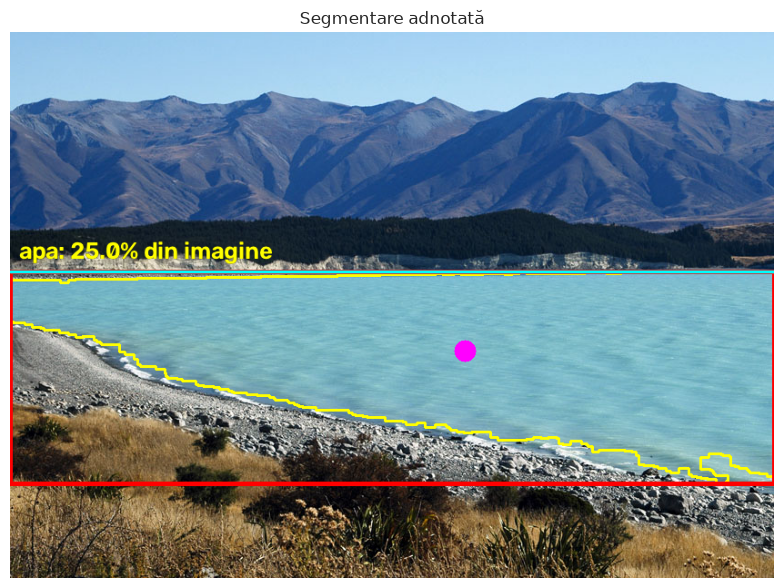

In [78]:
annotated = IMAGES['lac'].copy()
contours, _ = cv2.findContours(ref_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
largest = max(contours, key=cv2.contourArea)

x, y, w_box, h_box = cv2.boundingRect(largest)
m = cv2.moments(largest)
cx, cy = int(m['m10'] / m['m00']), int(m['m01'] / m['m00'])
area_pct = 100 * cv2.contourArea(largest) / (annotated.shape[0] * annotated.shape[1])

cv2.drawContours(annotated, [largest], -1, (0, 255, 255), 2)
cv2.rectangle(annotated, (x, y), (x + w_box, y + h_box), (0, 0, 255), 3)
cv2.circle(annotated, (cx, cy), 12, (255, 0, 255), -1)
cv2.line(annotated, (0, y), (annotated.shape[1], y), (255, 255, 0), 2, cv2.LINE_AA)   # „orizontul” = marginea de sus a apei

label = f'apa: {area_pct:.1f}% din imagine'
for color, thick in [((0, 0, 0), 6), ((0, 255, 255), 2)]:        # contur negru + text galben
    cv2.putText(annotated, label, (x + 10, max(30, y - 14)), cv2.FONT_HERSHEY_SIMPLEX, 0.9, color, thick, cv2.LINE_AA)

show([annotated], ['Segmentare adnotată'], size=8)

Colajul combină rezultatele de mai sus (≥ 3 concepte: gamma, spații de culori, segmentare/măști, adnotare, operații pe biți, praguri):
fiecare piesă e redimensionată la aceeași dimensiune (imaginile gri → 3 canale), primește o etichetă și e așezată în grilă cu `np.hstack` / `np.vstack`.

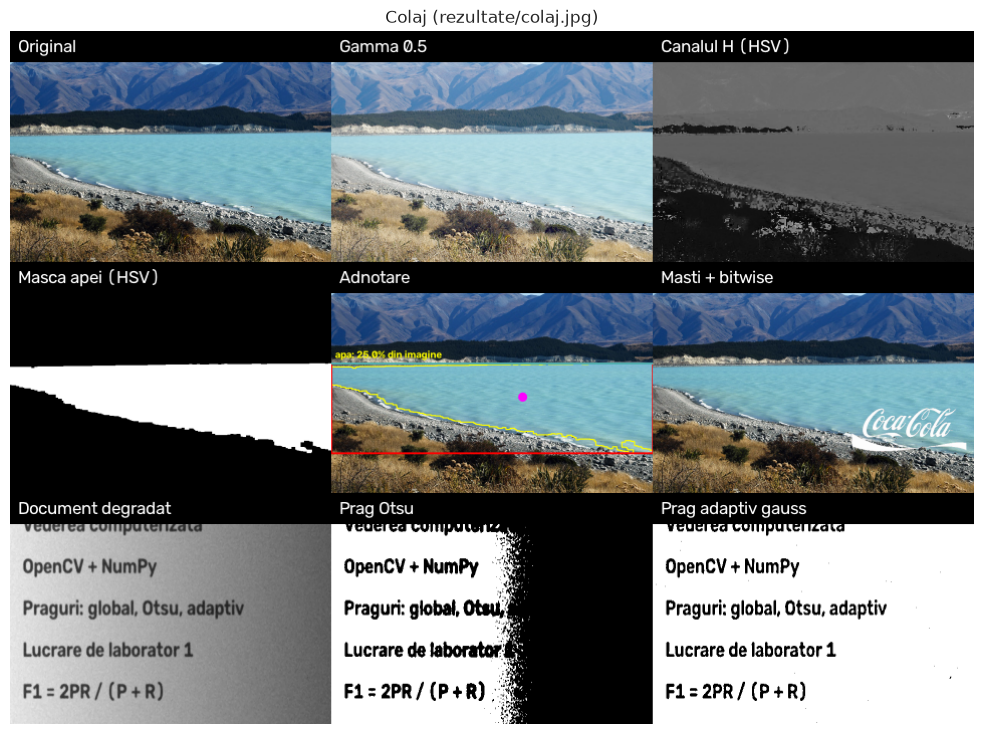

In [79]:
def make_collage(tiles, cols=3, tile_size=(320, 230)):
    canvases = []
    for image, label in tiles:
        tile = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR) if image.ndim == 2 else image
        tile = cv2.resize(tile, tile_size, interpolation=cv2.INTER_AREA)
        cv2.rectangle(tile, (0, 0), (tile_size[0], 30), (0, 0, 0), -1)
        cv2.putText(tile, label, (8, 21), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 1, cv2.LINE_AA)
        canvases.append(tile)
    while len(canvases) % cols:
        canvases.append(np.zeros_like(canvases[0]))
    rows = [np.hstack(canvases[i:i + cols]) for i in range(0, len(canvases), cols)]
    return np.vstack(rows)

collage = make_collage([
    (IMAGES['lac'], 'Original'),
    (variants['gamma 0.5'], 'Gamma 0.5'),
    (hh, 'Canalul H (HSV)'),
    (ref_mask, 'Masca apei (HSV)'),
    (annotated, 'Adnotare'),
    (watermarked, 'Masti + bitwise'),
    (degraded, 'Document degradat'),
    (METHODS['Otsu'](degraded), 'Prag Otsu'),
    (METHODS['adaptiv gauss'](degraded), 'Prag adaptiv gauss'),
])
cv2.imwrite(os.path.join(OUT_DIR, 'colaj.jpg'), collage)
show([collage], ['Colaj (rezultate/colaj.jpg)'], size=10)

## 6. Video: pipeline cadru cu cadru
Un video este o secvență de imagini citite cu `cv2.VideoCapture`. Clipul `roboti.mp4` conține containere albastre, detectate după culoare:
1. redimensionare la 50% (viteză);
2. BGR → HSV și `cv2.inRange` pentru albastru;
3. curățarea măștii prin morfologie (deschidere + închidere);
4. contururi → dreptunghiuri de încadrare (obiectele mici sunt ignorate) → adnotare;
5. scrierea cadrului cu `cv2.VideoWriter`.

Măsurăm timpul per cadru ca să vedem dacă pipeline-ul rulează în timp real (≥ FPS-ul clipului).
> Dacă `roboti.mp4` lipsește, se generează un clip sintetic (dreptunghi albastru în mișcare), ca notebook-ul să ruleze oricum.

In [80]:
def make_synthetic_clip(path, n=150, size=(640, 360), fps=30):
    w, h = size
    wr = cv2.VideoWriter(path, cv2.VideoWriter_fourcc(*'mp4v'), fps, (w, h))
    rng = np.random.default_rng(0)
    for i in range(n):
        frame = cv2.add(np.full((h, w, 3), 40, np.uint8), rng.integers(0, 20, (h, w, 3), dtype=np.uint8))
        xx = int(20 + (w - 160) * i / (n - 1))
        cv2.rectangle(frame, (xx, 120), (xx + 120, 220), (200, 90, 20), -1)   # obiect albastru (BGR)
        cv2.circle(frame, (w - xx // 2 - 30, 300), 25, (0, 0, 200), -1)         # distractor roșu
        wr.write(frame)
    wr.release()

if not os.path.exists(VIDEO_PATH):
    print(f'{VIDEO_PATH} lipsește -> generez clip_sintetic.mp4')
    VIDEO_PATH = 'clip_sintetic.mp4'
    make_synthetic_clip(VIDEO_PATH)

roboti.mp4 lipsește -> generez clip_sintetic.mp4


In [81]:
BLUE_LO, BLUE_HI = (95, 80, 60), (130, 255, 255)
KERNEL5 = np.ones((5, 5), np.uint8)
MIN_AREA = 150

def process_frame(frame):
    small = cv2.resize(frame, None, fx=0.5, fy=0.5, interpolation=cv2.INTER_AREA)
    mask = cv2.inRange(cv2.cvtColor(small, cv2.COLOR_BGR2HSV), BLUE_LO, BLUE_HI)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, KERNEL5)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, KERNEL5)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    boxes = [cv2.boundingRect(c) for c in contours if cv2.contourArea(c) >= MIN_AREA]
    for x, y, w, h in boxes:
        cv2.rectangle(small, (x, y), (x + w, y + h), (0, 255, 255), 2)
    return small, mask, len(boxes)

In [82]:
cap = cv2.VideoCapture(VIDEO_PATH)
assert cap.isOpened(), f'Nu pot deschide {VIDEO_PATH}'
fps_in = cap.get(cv2.CAP_PROP_FPS) or 30.0
n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
print(f'{VIDEO_PATH}: {width}x{height}, {fps_in:.0f} fps, {n_frames} cadre ({n_frames / fps_in:.1f} s)')

out_path = os.path.join(OUT_DIR, Path(VIDEO_PATH).stem + '_adnotat.mp4')
writer = None                      # creat la primul cadru, cu dimensiunea exactă a rezultatului
timing, samples = [], {}
idx = 0
while True:
    ok, frame = cap.read()
    if not ok:
        break
    start = time.perf_counter()
    result, mask, n_obj = process_frame(frame)
    ms = (time.perf_counter() - start) * 1000

    cv2.putText(result, f'cadru {idx} obiecte: {n_obj} {ms:.1f} ms', (10, 25),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2, cv2.LINE_AA)
    if writer is None:
        writer = cv2.VideoWriter(out_path, cv2.VideoWriter_fourcc(*'mp4v'), fps_in,
                                 (result.shape[1], result.shape[0]))
    writer.write(result)

    timing.append({'cadru': idx, 'timp_ms': ms, 'obiecte': n_obj})
    if idx % 100 == 0:
        samples[idx] = (result, mask)
    idx += 1

cap.release()
if writer is not None:
    writer.release()

video_df = pd.DataFrame(timing)
save_json(video_df, 'video_timing.json')
print(f'Salvat: {out_path} ({idx} cadre)')

clip_sintetic.mp4: 640x360, 30 fps, 150 cadre (5.0 s)
Salvat: rezultate/video_timing.json
Salvat: rezultate/clip_sintetic_adnotat.mp4 (150 cadre)


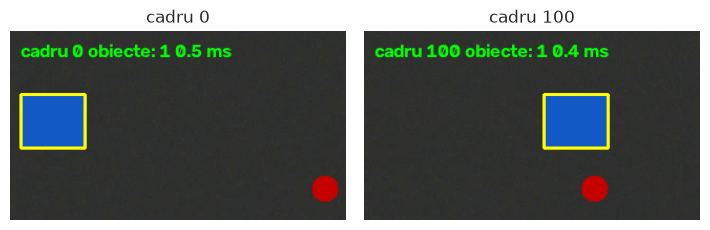

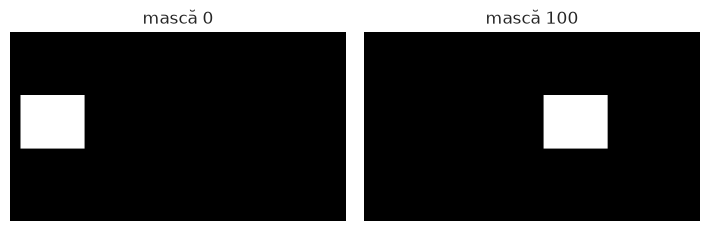

In [83]:
show([r for r, _ in samples.values()], [f'cadru {i}' for i in samples], cols=3, size=3.6)
show([m for _, m in samples.values()], [f'mască {i}' for i in samples], cols=3, size=3.6)

In [84]:
video_stats = pd.Series({
    'cadre': len(video_df),
    'timp_mediu_ms': video_df.timp_ms.mean(),
    'timp_median_ms': video_df.timp_ms.median(),
    'timp_p95_ms': video_df.timp_ms.quantile(0.95),
    'fps_procesare': 1000 / video_df.timp_ms.mean(),
    'fps_clip': fps_in,
    'obiecte_medii_per_cadru': video_df.obiecte.mean(),
}).round(2)
video_stats

cadre                       150.00
timp_mediu_ms                 0.46
timp_median_ms                0.41
timp_p95_ms                   0.62
fps_procesare              2183.65
fps_clip                     30.00
obiecte_medii_per_cadru       1.00
dtype: float64

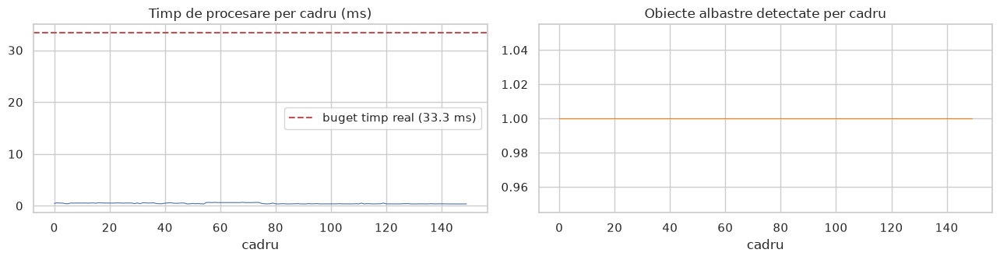

In [85]:
budget_ms = 1000 / fps_in
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].plot(video_df.cadru, video_df.timp_ms, lw=0.8)
axes[0].axhline(budget_ms, color='r', ls='--', label=f'buget timp real ({budget_ms:.1f} ms)')
axes[0].set_title('Timp de procesare per cadru (ms)'); axes[0].set_xlabel('cadru'); axes[0].legend()
axes[1].plot(video_df.cadru, video_df.obiecte, lw=0.8, color='tab:orange')
axes[1].set_title('Obiecte albastre detectate per cadru'); axes[1].set_xlabel('cadru')
plt.tight_layout()
plt.show()

## 7. Agregarea rezultatelor
Toate experimentele au fost salvate în `rezultate/*.json`. Le reîncărcăm și extragem indicatorii principali într-un singur tabel, ca bază pentru concluzii.

In [86]:
results = {Path(f).stem: pd.read_json(f) for f in sorted(glob(os.path.join(OUT_DIR, '*.json')))}
print({k: len(v) for k, v in results.items()})

interp = results['interpolare'].groupby(['rol', 'metoda']).mean(numeric_only=True)
shrink_res, enlarge_res = interp.loc['micsorare'], interp.loc['marire']
color = results['segmentare_culoare'].set_index('iluminare')
praguri = results['praguri'].groupby('metoda').F1.agg(['mean', 'min'])
bc = results['luminozitate_contrast'].set_index('varianta')

summary = pd.Series({
    'micsorare: cel mai bun PSNR / SSIM': f"{shrink_res.psnr.idxmax()} / {shrink_res.ssim.idxmax()}",
    'marire: cel mai bun PSNR / SSIM': f"{enlarge_res.psnr.idxmax()} / {enlarge_res.ssim.idxmax()}",
    'marire: cea mai rapida / cea mai lenta': f"{enlarge_res.timp_ms.idxmin()} / {enlarge_res.timp_ms.idxmax()}",
    'luminozitate: varianta cu cei mai multi pixeli saturati': f"{bc['saturati_%'].idxmax()} ({bc['saturati_%'].max():.2f}%)",
    'segmentare culoare: IoU mediu RGB / HSV': f"{color.IoU_RGB.mean():.3f} / {color.IoU_HSV.mean():.3f}",
    'segmentare culoare: IoU minim RGB / HSV': f"{color.IoU_RGB.min():.3f} / {color.IoU_HSV.min():.3f}",
    'praguri: F1 mediu (cea mai buna metoda)': f"{praguri['mean'].idxmax()} ({praguri['mean'].max():.3f})",
    'praguri: F1 minim (cea mai slaba metoda)': f"{praguri['min'].idxmin()} ({praguri['min'].min():.3f})",
    'video: fps procesare / fps clip': f"{video_stats.fps_procesare:.0f} / {fps_in:.0f}",
})
summary_df = summary.to_frame('valoare')
summary_df.reset_index().rename(columns={'index': 'indicator'}).to_json(
    os.path.join(OUT_DIR, 'rezumat.json.txt'), orient='records', indent=4, force_ascii=False)
summary_df

{'atribute': 10, 'interpolare': 50, 'luminozitate_contrast': 8, 'praguri': 20, 'scena_intunecata': 5, 'segmentare_culoare': 12, 'video_timing': 150}


,valoare
micsorare: cel mai bun PSNR / SSIM,AREA / AREA
marire: cel mai bun PSNR / SSIM,LANCZOS4 / LANCZOS4
marire: cea mai rapida / cea mai lenta,NEAREST / LANCZOS4
luminozitate: varianta cu cei mai multi pixeli saturati,contrast x1.6 (33.41%)
segmentare culoare: IoU mediu RGB / HSV,0.257 / 0.735
segmentare culoare: IoU minim RGB / HSV,0.000 / 0.061
praguri: F1 mediu (cea mai buna metoda),adaptiv gauss (0.958)
praguri: F1 minim (cea mai slaba metoda),Otsu (0.219)
video: fps procesare / fps clip,2184 / 30


## Concluzii
> **Important:** concluziile trebuie să se bazeze pe valorile **voastre** măsurate (tabelele de mai sus), nu pe impresii vizuale.
> Înlocuiți `[...]` cu cifrele obținute după rulare.

**Interpolare — metoda potrivită depinde de direcție**
- La micșorare, `INTER_AREA` dă cea mai bună calitate (PSNR ≈ [...] dB, SSIM ≈ [...]) pentru că mediază toți pixelii acoperiți; `INTER_NEAREST` este cea mai rapidă, dar produce aliasing (PSNR ≈ [...]).
- La mărire, `LANCZOS4` și `CUBIC` sunt aproape la egalitate (PSNR ≈ [...]), dar `LANCZOS4` e de ≈ [...]× mai lent; `AREA` la mărire se comportă ca `NEAREST`.
- Compromis recomandat: `AREA` pentru micșorare, `CUBIC` pentru mărire.

**Luminozitate și contrast — saturarea înseamnă pierdere de informație**
- Adunarea NumPy pe `uint8` produce wrap-around (culori false); `cv2.add` / `cv2.convertScaleAbs` saturează corect (echivalent cu `np.clip`).
- Contrastul ×1.6 saturează ≈ [...]% din pixeli, +60 la luminozitate ≈ [...]%; gamma 0.5 ridică media ([...] → [...]) fără pixeli saturați suplimentari — varianta sigură pentru scene întunecate (confirmat pe `scena_intunecata`: [...]).

**Spații de culori — nuanța e stabilă la intensitate, nu și la culoarea luminii**
- Pe pixelii apei, gamma și scalarea luminozității modifică B, G, R cu [...] unități, dar H cu sub [...] unități.
- Pragurile RGB eșuează la schimbări de intensitate (IoU mediu [...]); HSV păstrează IoU [...] pentru gamma 0.8–2.0 și luminozitate ×0.5–×1.2.
- HSV eșuează la (a) supraexpunere / gamma mic (saturația scade, clipping-ul distorsionează nuanța) și (b) schimbarea culorii luminii — acolo e nevoie de corecția balansului de alb.

**Praguri — la iluminare neuniformă, pragul adaptiv**
- Fără gradient (≤ 0.2), global și Otsu sunt cele mai bune (F1 ≈ [...]) — histograma e clar bimodală.
- De la gradient [...] Otsu și pragul global se prăbușesc (F1 ≈ [...]); adaptivul gaussian rămâne stabil (F1 ≈ [...]).

**Video — timp real**
- La rezoluție înjumătățită, un cadru se procesează în ≈ [...] ms (≈ [...] FPS), adică de ≈ [...]× sub bugetul de [...] ms al clipului.

---